#Data PreProcessing



In [ ]:
import yfinance as yf

ticker = yf.Ticker("BBRI.JK")
df = ticker.history(start="2019-01-01", end="2025-12-31")
df[['Open','High','Low','Close']].to_csv("BBRI_2019_2025.csv")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM

In [ ]:
data_saham = pd.read_csv('/content/BBRI_2019_2025.csv', parse_dates=['Date'], sep=',', index_col='Date')


In [ ]:
data_saham

,Open,High,Low,Close
Date,,,,
2019-01-01 00:00:00+07:00,2286.934082,2286.934082,2286.934082,2286.934082
2019-01-02 00:00:00+07:00,2255.691406,2274.436737,2243.194575,2255.691406
2019-01-03 00:00:00+07:00,2236.946352,2274.437018,2236.946352,2261.940186
2019-01-04 00:00:00+07:00,2261.940248,2286.934082,2255.691747,2286.934082
2019-01-07 00:00:00+07:00,2311.927916,2318.176249,2286.934082,2286.934082
...,...,...,...,...
2025-12-22 00:00:00+07:00,3633.362420,3642.999986,3614.087287,3623.724854
2025-12-23 00:00:00+07:00,3623.724982,3643.000115,3594.812283,3633.362549
2025-12-24 00:00:00+07:00,3633.362549,3652.637682,3614.087416,3633.362549


Text(0.5, 1.0, 'Harga Buka Saham BBRI')

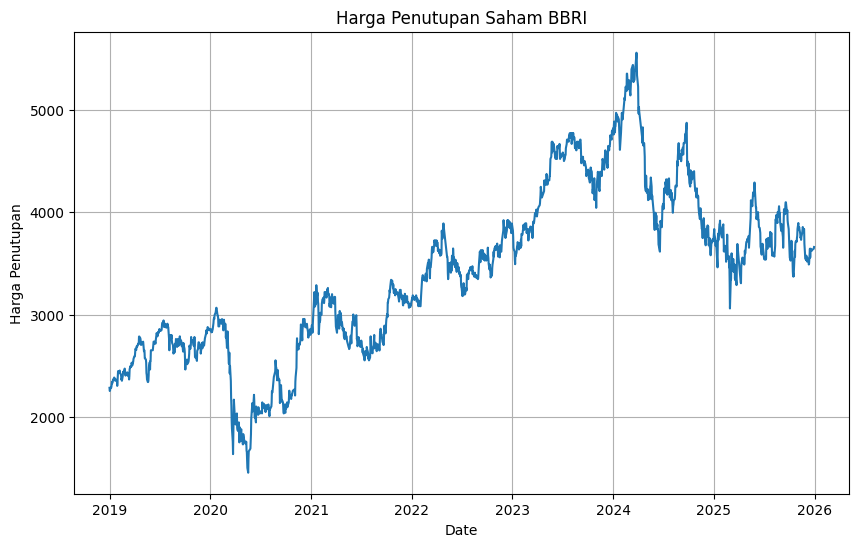

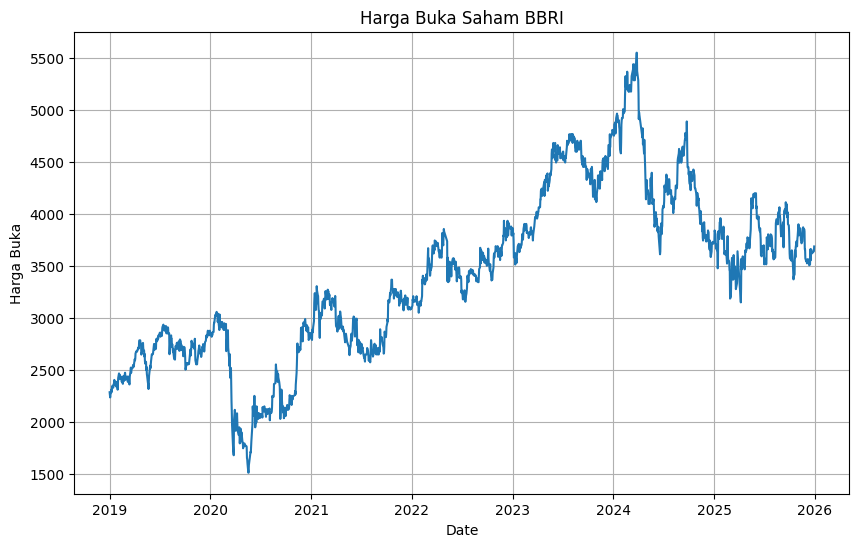

In [ ]:
#Satu Fitur
df_close = data_saham['Close']
df_open = data_saham['Open']
df_high = data_saham['High']
df_low = data_saham['Low']

#Dua Fitur
df_open_close = data_saham[['Open','Close']]
df_high_close = data_saham[['High','Close']]
df_low_close = data_saham[['Low','Close']]
df_open_high = data_saham[['Open','High']]
df_open_low = data_saham[['Open','Low']]
df_high_low = data_saham[['High','Low']]

#Tiga Fitur
df_open_high_close = data_saham[['Open','High','Close']]
df_open_low_close = data_saham[['Open','Low','Close']]
df_high_low_close = data_saham[['High','Low','Close']]
df_open_high_low = data_saham[['Open','High','Low']]

#Empat Fitur
df_open_high_low_close = data_saham[['Open','High','Low','Close']]

plt.figure(figsize=(10,6))
plt.grid()
plt.plot(df_close)
plt.xlabel('Date')
plt.ylabel('Harga Penutupan')
plt.title('Harga Penutupan Saham BBRI')

plt.figure(figsize=(10,6))
plt.grid()
plt.plot(df_open)
plt.xlabel('Date')
plt.ylabel('Harga Buka')
plt.title('Harga Buka Saham BBRI')

In [ ]:
df_low

,Low
Date,
2019-01-01 00:00:00+07:00,2286.934082
2019-01-02 00:00:00+07:00,2243.194575
2019-01-03 00:00:00+07:00,2236.946352
2019-01-04 00:00:00+07:00,2255.691747
2019-01-07 00:00:00+07:00,2286.934082
...,...
2025-12-22 00:00:00+07:00,3614.087287
2025-12-23 00:00:00+07:00,3594.812283
2025-12-24 00:00:00+07:00,3614.087416


<Figure size 640x480 with 0 Axes>

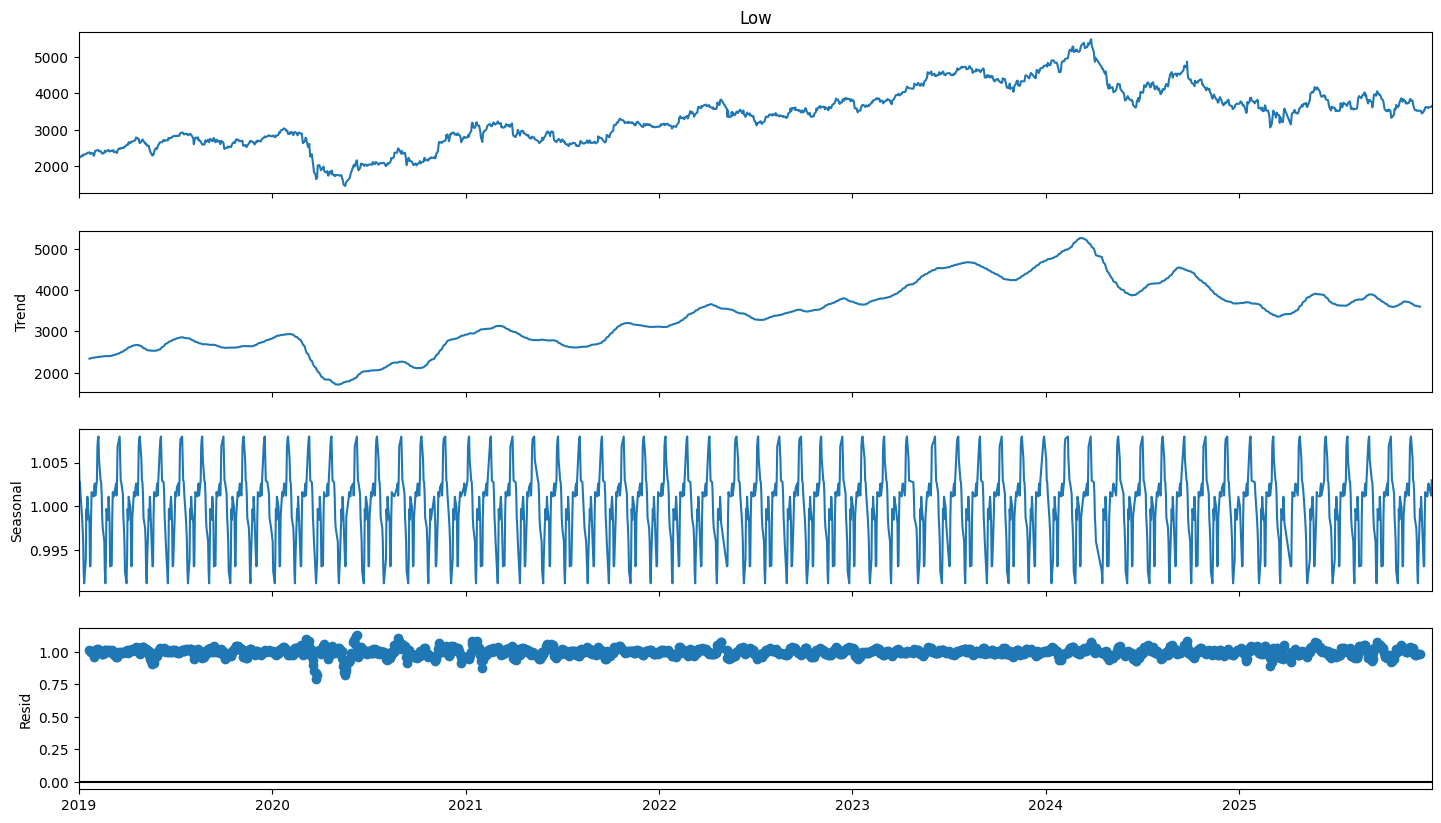

In [ ]:
#GANTI
result = seasonal_decompose(df_low, model='multiplicative',period=28)
fig = plt.figure()
fig = result.plot()
fig.set_size_inches(16, 9)

Text(0.5, 1.0, 'Transformed data')

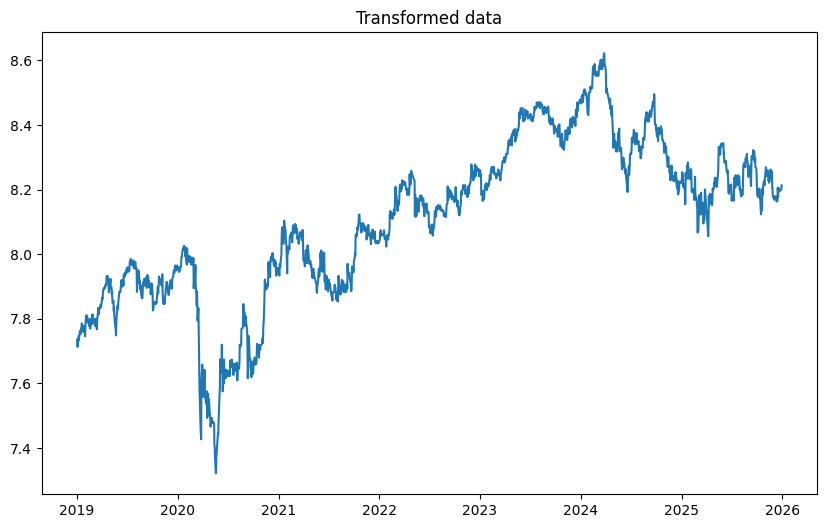

In [ ]:
#Untuk mengecilkan skala menggunakan fungsi Log tapi masih mempertahankan karakter data
df_close_log = np.log(df_close)
df_open_log = np.log(df_open)
df_high_log = np.log(df_high)
df_low_log = np.log(df_low)
df_open_close_log = np.log(df_open_close)
df_high_close_log = np.log(df_high_close)
df_low_close_log = np.log(df_low_close)
df_open_high_log = np.log(df_open_high)
df_open_low_log = np.log(df_open_low)
df_high_low_log = np.log(df_high_low)
df_open_high_close_log = np.log(df_open_high_close)
df_open_low_close_log = np.log(df_open_low_close)
df_high_low_close_log = np.log(df_high_low_close)
df_open_high_low_log = np.log(df_open_high_low)
df_open_high_low_close_log = np.log(df_open_high_low_close)

plt.figure(figsize = (10,6))
plt.plot(df_open_log)
plt.title('Transformed data')

In [ ]:
from sklearn.model_selection import train_test_split

# Mengumpulkan semua dataset
datasets = {
    "open": df_open_log,
    "high": df_high_log,
    "low": df_low_log,
    "close": df_close_log,

    "open_close": df_open_close_log,
    "open_high": df_open_high_log,
    "open_low": df_open_low_log,
    "high_low": df_high_low_log,
    "low_close": df_low_close_log,
    "high_close": df_high_close_log,

    "open_high_low": df_open_high_low_log,
    "open_low_close": df_open_low_close_log,
    "open_high_close": df_open_high_close_log,
    "high_low_close": df_high_low_close_log,

    "open_high_low_close": df_open_high_low_close_log
}

splits = {}

for name, df in datasets.items():

    # split train dan sementara (val+test)
    train, temp = train_test_split(df, test_size=0.30, shuffle=False)

    # split validation dan test
    val, test = train_test_split(temp, test_size=0.50, shuffle=False)

    splits[name] = {
        "train": train,
        "validation": val,
        "test": test
    }

# Satu fitur
train_open = splits["open"]["train"]
val_open = splits["open"]["validation"]
test_open = splits["open"]["test"]

train_high = splits["high"]["train"]
val_high = splits["high"]["validation"]
test_high = splits["high"]["test"]

train_low = splits["low"]["train"]
val_low = splits["low"]["validation"]
test_low = splits["low"]["test"]

train_close = splits["close"]["train"]
val_close = splits["close"]["validation"]
test_close = splits["close"]["test"]

# Dua Fitur
train_open_close = splits["open_close"]["train"]
val_open_close = splits["open_close"]["validation"]
test_open_close = splits["open_close"]["test"]

train_open_high = splits["open_high"]["train"]
val_open_high = splits["open_high"]["validation"]
test_open_high = splits["open_high"]["test"]

train_open_low = splits["open_low"]["train"]
val_open_low = splits["open_low"]["validation"]
test_open_low = splits["open_low"]["test"]

train_high_low = splits["high_low"]["train"]
val_high_low = splits["high_low"]["validation"]
test_high_low = splits["high_low"]["test"]

train_high_close = splits["high_close"]["train"]
val_high_close = splits["high_close"]["validation"]
test_high_close = splits["high_close"]["test"]

train_low_close = splits["low_close"]["train"]
val_low_close = splits["low_close"]["validation"]
test_low_close = splits["low_close"]["test"]

# Tiga fitur
train_open_high_low = splits["open_high_low"]["train"]
val_open_high_low = splits["open_high_low"]["validation"]
test_open_high_low = splits["open_high_low"]["test"]

train_open_high_close = splits["open_high_close"]["train"]
val_open_high_close = splits["open_high_close"]["validation"]
test_open_high_close = splits["open_high_close"]["test"]

train_open_low_close = splits["open_low_close"]["train"]
val_open_low_close = splits["open_low_close"]["validation"]
test_open_low_close = splits["open_low_close"]["test"]

train_high_low_close = splits["high_low_close"]["train"]
val_high_low_close = splits["high_low_close"]["validation"]
test_high_low_close = splits["high_low_close"]["test"]

# Empat Fitur
train_open_high_low_close = splits["open_high_low_close"]["train"]
val_open_high_low_close = splits["open_high_low_close"]["validation"]
test_open_high_low_close = splits["open_high_low_close"]["test"]

In [ ]:
train_open

,Open
Date,
2019-01-01 00:00:00+07:00,7.734967
2019-01-02 00:00:00+07:00,7.721212
2019-01-03 00:00:00+07:00,7.712867
2019-01-04 00:00:00+07:00,7.723978
2019-01-07 00:00:00+07:00,7.745837
...,...
2023-10-27 00:00:00+07:00,8.328961
2023-10-30 00:00:00+07:00,8.335004
2023-10-31 00:00:00+07:00,8.335004


In [ ]:
val_open

,Open
Date,
2023-11-03 00:00:00+07:00,8.343999
2023-11-06 00:00:00+07:00,8.358814
2023-11-07 00:00:00+07:00,8.383028
2023-11-08 00:00:00+07:00,8.378232
2023-11-09 00:00:00+07:00,8.383028
...,...
2024-11-21 00:00:00+07:00,8.235718
2024-11-22 00:00:00+07:00,8.228684
2024-11-25 00:00:00+07:00,8.267904


In [ ]:
test_open

,Open
Date,
2024-11-29 00:00:00+07:00,8.235718
2024-12-02 00:00:00+07:00,8.233378
2024-12-03 00:00:00+07:00,8.226328
2024-12-04 00:00:00+07:00,8.226328
2024-12-05 00:00:00+07:00,8.242703
...,...
2025-12-22 00:00:00+07:00,8.197914
2025-12-23 00:00:00+07:00,8.195258
2025-12-24 00:00:00+07:00,8.197914


In [ ]:
train_open_close

,Open,Close
Date,,
2019-01-01 00:00:00+07:00,7.734967,7.734967
2019-01-02 00:00:00+07:00,7.721212,7.721212
2019-01-03 00:00:00+07:00,7.712867,7.723978
2019-01-04 00:00:00+07:00,7.723978,7.734967
2019-01-07 00:00:00+07:00,7.745837,7.734967
...,...,...
2023-10-27 00:00:00+07:00,8.328961,8.339012
2023-10-30 00:00:00+07:00,8.335004,8.339012
2023-10-31 00:00:00+07:00,8.335004,8.330979


In [ ]:
# Standarisasi data MinMaxScaler

from sklearn.preprocessing import MinMaxScaler

scaled_splits = {}

for name, data in splits.items():

    train = data["train"]
    val = data["validation"]
    test = data["test"]

    scaler = MinMaxScaler()

    # Ensure the input to scaler is 2-dimensional
    # If it's a pandas Series, convert it to a DataFrame with a single column
    if isinstance(train, pd.Series):
        train = train.to_frame()
        val = val.to_frame()
        test = test.to_frame()

    # fit hanya pada train
    scaler.fit(train)

    # transform
    train_scaled = scaler.transform(train)
    val_scaled = scaler.transform(val)
    test_scaled = scaler.transform(test)

    scaled_splits[name] = {
        "train": train_scaled,
        "validation": val_scaled,
        "test": test_scaled,
        "scaler": scaler
    }

# Satu fitur
train_scaled_open = scaled_splits["open"]["train"]
val_scaled_open = scaled_splits["open"]["validation"]
test_scaled_open = scaled_splits["open"]["test"]

train_scaled_high = scaled_splits["high"]["train"]
val_scaled_high = scaled_splits["high"]["validation"]
test_scaled_high = scaled_splits["high"]["test"]

train_scaled_low = scaled_splits["low"]["train"]
val_scaled_low = scaled_splits["low"]["validation"]
test_scaled_low = scaled_splits["low"]["test"]

train_scaled_close = scaled_splits["close"]["train"]
val_scaled_close = scaled_splits["close"]["validation"]
test_scaled_close = scaled_splits["close"]["test"]

# Dua Fitur
train_scaled_open_close = scaled_splits["open_close"]["train"]
val_scaled_open_close = scaled_splits["open_close"]["validation"]
test_scaled_open_close = scaled_splits["open_close"]["test"]

train_scaled_open_high = scaled_splits["open_high"]["train"]
val_scaled_open_high = scaled_splits["open_high"]["validation"]
test_scaled_open_high = scaled_splits["open_high"]["test"]

train_scaled_open_low = scaled_splits["open_low"]["train"]
val_scaled_open_low = scaled_splits["open_low"]["validation"]
test_scaled_open_low = scaled_splits["open_low"]["test"]

train_scaled_high_low = scaled_splits["high_low"]["train"]
val_scaled_high_low = scaled_splits["high_low"]["validation"]
test_scaled_high_low = scaled_splits["high_low"]["test"]

train_scaled_high_close = scaled_splits["high_close"]["train"]
val_scaled_high_close = scaled_splits["high_close"]["validation"]
test_scaled_high_close = scaled_splits["high_close"]["test"]

train_scaled_low_close = scaled_splits["low_close"]["train"]
val_scaled_low_close = scaled_splits["low_close"]["validation"]
test_scaled_low_close = scaled_splits["low_close"]["test"]

# Tiga Fitur
train_scaled_open_high_low = scaled_splits["open_high_low"]["train"]
val_scaled_open_high_low = scaled_splits["open_high_low"]["validation"]
test_scaled_open_high_low = scaled_splits["open_high_low"]["test"]

train_scaled_open_high_close = scaled_splits["open_high_close"]["train"]
val_scaled_open_high_close = scaled_splits["open_high_close"]["validation"]
test_scaled_open_high_close = scaled_splits["open_high_close"]["test"]

train_scaled_open_low_close = scaled_splits["open_low_close"]["train"]
val_scaled_open_low_close = scaled_splits["open_low_close"]["validation"]
test_scaled_open_low_close = scaled_splits["open_low_close"]["test"]

train_scaled_high_low_close = scaled_splits["high_low_close"]["train"]
val_scaled_high_low_close = scaled_splits["high_low_close"]["validation"]
test_scaled_high_low_close = scaled_splits["high_low_close"]["test"]

# Empat Fitur
train_scaled_open_high_low_close = scaled_splits["open_high_low_close"]["train"]
val_scaled_open_high_low_close = scaled_splits["open_high_low_close"]["validation"]
test_scaled_open_high_low_close = scaled_splits["open_high_low_close"]["test"]


In [ ]:
train_scaled_close

array([[0.37947952],
       [0.3678676 ],
       [0.37020289],
       ...,
       [0.88261046],
       [0.86019013],
       [0.88939103]])

In [ ]:
test_close.shape

(256,)

In [ ]:
train_scaled_open

array([[0.35991788],
       [0.3479399 ],
       [0.34067344],
       ...,
       [0.88241384],
       [0.87185888],
       [0.87539154]])

In [ ]:
train_scaled_open_high_low_close

array([[0.35991788, 0.35224729, 0.38330642, 0.37947952],
       [0.3479399 , 0.34747526, 0.36700779, 0.3678676 ],
       [0.34067344, 0.34747537, 0.36465361, 0.37020289],
       ...,
       [0.88241384, 0.87828654, 0.8863425 , 0.88261046],
       [0.87185888, 0.87129163, 0.8639264 , 0.86019013],
       [0.87539154, 0.89125259, 0.87779134, 0.88939103]])

In [ ]:
train_scaled_open_high_low_close[1]

array([0.3479399 , 0.34747526, 0.36700779, 0.3678676 ])

In [ ]:
#GANTI
# Pembentukan Sequence untuk target / y_train (harga pembukaan)

y_low_train = scaled_splits["low"]["train"]

import numpy as np

def create_sequences(features, target, seq_length=7):

    X = []
    y = []

    for i in range(len(features) - seq_length):
        X.append(features[i:i+seq_length])
        y.append(target[i+seq_length])

    return np.array(X), np.array(y)

In [ ]:
#GANTI
# Pembentukan Sequence untuk X_train

train_sequences = {}

for name, data in scaled_splits.items():

    X_data = data["train"]

    X_train, y_train = create_sequences(
        X_data,
        y_low_train,
        seq_length=7
    )

    train_sequences[name] = {
        "X_train": X_train,
        "y_train": y_train
    }

In [ ]:
# Shape sequence train

for name in train_sequences:

    print(name)
    print("X_train:", train_sequences[name]["X_train"].shape)
    print("y_train:", train_sequences[name]["y_train"].shape)
    print()

open
X_train: (1186, 7, 1)
y_train: (1186, 1)

high
X_train: (1186, 7, 1)
y_train: (1186, 1)

low
X_train: (1186, 7, 1)
y_train: (1186, 1)

close
X_train: (1186, 7, 1)
y_train: (1186, 1)

open_close
X_train: (1186, 7, 2)
y_train: (1186, 1)

open_high
X_train: (1186, 7, 2)
y_train: (1186, 1)

open_low
X_train: (1186, 7, 2)
y_train: (1186, 1)

high_low
X_train: (1186, 7, 2)
y_train: (1186, 1)

low_close
X_train: (1186, 7, 2)
y_train: (1186, 1)

high_close
X_train: (1186, 7, 2)
y_train: (1186, 1)

open_high_low
X_train: (1186, 7, 3)
y_train: (1186, 1)

open_low_close
X_train: (1186, 7, 3)
y_train: (1186, 1)

open_high_close
X_train: (1186, 7, 3)
y_train: (1186, 1)

high_low_close
X_train: (1186, 7, 3)
y_train: (1186, 1)

open_high_low_close
X_train: (1186, 7, 4)
y_train: (1186, 1)



In [ ]:
# Data siap pakai train

# Satu fitur
X_train_open = train_sequences["open"]["X_train"]
y_train_open = train_sequences["open"]["y_train"]

X_train_high = train_sequences["high"]["X_train"]
y_train_high = train_sequences["high"]["y_train"]

X_train_low = train_sequences["low"]["X_train"]
y_train_low = train_sequences["low"]["y_train"]

X_train_close = train_sequences["close"]["X_train"]
y_train_close = train_sequences["close"]["y_train"]

# Dua Fitur
X_train_open_high = train_sequences["open_high"]["X_train"]
y_train_open_high = train_sequences["open_high"]["y_train"]

X_train_open_low = train_sequences["open_low"]["X_train"]
y_train_open_low = train_sequences["open_low"]["y_train"]

X_train_high_low = train_sequences["high_low"]["X_train"]
y_train_high_low = train_sequences["high_low"]["y_train"]

X_train_open_close = train_sequences["open_close"]["X_train"]
y_train_open_close = train_sequences["open_close"]["y_train"]

X_train_high_close = train_sequences["high_close"]["X_train"]
y_train_high_close = train_sequences["high_close"]["y_train"]

X_train_low_close = train_sequences["low_close"]["X_train"]
y_train_low_close = train_sequences["low_close"]["y_train"]

# Tiga Fitur
X_train_open_high_low = train_sequences["open_high_low"]["X_train"]
y_train_open_high_low = train_sequences["open_high_low"]["y_train"]

X_train_open_high_close = train_sequences["open_high_close"]["X_train"]
y_train_open_high_close = train_sequences["open_high_close"]["y_train"]

X_train_open_low_close = train_sequences["open_low_close"]["X_train"]
y_train_open_low_close = train_sequences["open_low_close"]["y_train"]

X_train_high_low_close = train_sequences["high_low_close"]["X_train"]
y_train_high_low_close = train_sequences["high_low_close"]["y_train"]

# Empat Fitur
X_train_open_high_low_close = train_sequences["open_high_low_close"]["X_train"]
y_train_open_high_low_close = train_sequences["open_high_low_close"]["y_train"]


In [ ]:
X_train_open[0]

array([[0.35991788],
       [0.3479399 ],
       [0.34067344],
       [0.35034883],
       [0.36938292],
       [0.35991779],
       [0.37173298]])

In [ ]:
X_train_open[1]

array([[0.3479399 ],
       [0.34067344],
       [0.35034883],
       [0.36938292],
       [0.35991779],
       [0.37173298],
       [0.37874615]])

In [ ]:
y_train_open[0]

array([0.39475846])

In [ ]:
X_train_open_high_low_close[0]

array([[0.35991788, 0.35224729, 0.38330642, 0.37947952],
       [0.3479399 , 0.34747526, 0.36700779, 0.3678676 ],
       [0.34067344, 0.34747537, 0.36465361, 0.37020289],
       [0.35034883, 0.35224729, 0.37169681, 0.37947952],
       [0.36938292, 0.36406375, 0.38330642, 0.37947952],
       [0.35991779, 0.35699302, 0.37635977, 0.38407976],
       [0.37173298, 0.37107727, 0.39019611, 0.39320587]])

In [ ]:
X_train_open_high_low_close[1]

array([[0.3479399 , 0.34747526, 0.36700779, 0.3678676 ],
       [0.34067344, 0.34747537, 0.36465361, 0.37020289],
       [0.35034883, 0.35224729, 0.37169681, 0.37947952],
       [0.36938292, 0.36406375, 0.38330642, 0.37947952],
       [0.35991779, 0.35699302, 0.37635977, 0.38407976],
       [0.37173298, 0.37107727, 0.39019611, 0.39320587],
       [0.37874615, 0.37340288, 0.39475846, 0.3999865 ]])

In [ ]:
y_train

array([[0.39475846],
       [0.39248032],
       [0.39929601],
       ...,
       [0.8863425 ],
       [0.8639264 ],
       [0.87779134]])

In [ ]:
print(X_train_open.shape)
print(y_train_open.shape)

print(X_train_open_high_low_close.shape)
print(y_train_open_high_low_close.shape)

(1186, 7, 1)
(1186, 1)
(1186, 7, 4)
(1186, 1)


In [ ]:
#GANTI
# Pembentukan Sequnce data Validation dan data test

y_low_val = scaled_splits["low"]["validation"]
y_low_test = scaled_splits["low"]["test"]

val_sequences = {}
test_sequences = {}

for name, data in scaled_splits.items():

    val_data = data["validation"]
    test_data = data["test"]

    X_val, y_val = create_sequences(val_data, y_low_val, seq_length=7)
    X_test, y_test = create_sequences(test_data, y_low_test, seq_length=7)

    val_sequences[name] = {
        "X_val": X_val,
        "y_val": y_val
    }

    test_sequences[name] = {
        "X_test": X_test,
        "y_test": y_test
    }

In [ ]:
# Shape sequence validation

for name in val_sequences:

    print(name)
    print("X_val:", val_sequences[name]["X_val"].shape)
    print("y_val:", val_sequences[name]["y_val"].shape)
    print()

open
X_val: (249, 7, 1)
y_val: (249, 1)

high
X_val: (249, 7, 1)
y_val: (249, 1)

low
X_val: (249, 7, 1)
y_val: (249, 1)

close
X_val: (249, 7, 1)
y_val: (249, 1)

open_close
X_val: (249, 7, 2)
y_val: (249, 1)

open_high
X_val: (249, 7, 2)
y_val: (249, 1)

open_low
X_val: (249, 7, 2)
y_val: (249, 1)

high_low
X_val: (249, 7, 2)
y_val: (249, 1)

low_close
X_val: (249, 7, 2)
y_val: (249, 1)

high_close
X_val: (249, 7, 2)
y_val: (249, 1)

open_high_low
X_val: (249, 7, 3)
y_val: (249, 1)

open_low_close
X_val: (249, 7, 3)
y_val: (249, 1)

open_high_close
X_val: (249, 7, 3)
y_val: (249, 1)

high_low_close
X_val: (249, 7, 3)
y_val: (249, 1)

open_high_low_close
X_val: (249, 7, 4)
y_val: (249, 1)



In [ ]:
# Shape sequence test

for name in val_sequences:

    print(name)
    print("X_test:", test_sequences[name]["X_test"].shape)
    print("y_test:", test_sequences[name]["y_test"].shape)
    print()

open
X_test: (249, 7, 1)
y_test: (249, 1)

high
X_test: (249, 7, 1)
y_test: (249, 1)

low
X_test: (249, 7, 1)
y_test: (249, 1)

close
X_test: (249, 7, 1)
y_test: (249, 1)

open_close
X_test: (249, 7, 2)
y_test: (249, 1)

open_high
X_test: (249, 7, 2)
y_test: (249, 1)

open_low
X_test: (249, 7, 2)
y_test: (249, 1)

high_low
X_test: (249, 7, 2)
y_test: (249, 1)

low_close
X_test: (249, 7, 2)
y_test: (249, 1)

high_close
X_test: (249, 7, 2)
y_test: (249, 1)

open_high_low
X_test: (249, 7, 3)
y_test: (249, 1)

open_low_close
X_test: (249, 7, 3)
y_test: (249, 1)

open_high_close
X_test: (249, 7, 3)
y_test: (249, 1)

high_low_close
X_test: (249, 7, 3)
y_test: (249, 1)

open_high_low_close
X_test: (249, 7, 4)
y_test: (249, 1)



In [ ]:
# Data Siap Pakai validation

# Satu Fitur
X_val_open = val_sequences["open"]["X_val"]
y_val_open = val_sequences["open"]["y_val"]

X_val_high = val_sequences["high"]["X_val"]
y_val_high = val_sequences["high"]["y_val"]

X_val_low = val_sequences["low"]["X_val"]
y_val_low = val_sequences["low"]["y_val"]

X_val_close = val_sequences["close"]["X_val"]
y_val_close = val_sequences["close"]["y_val"]

# Dua Fitur
X_val_open_high = val_sequences["open_high"]["X_val"]
y_val_open_high = val_sequences["open_high"]["y_val"]

X_val_open_low = val_sequences["open_low"]["X_val"]
y_val_open_low = val_sequences["open_low"]["y_val"]

X_val_high_low = val_sequences["high_low"]["X_val"]
y_val_high_low = val_sequences["high_low"]["y_val"]

X_val_open_close = val_sequences["open_close"]["X_val"]
y_val_open_close = val_sequences["open_close"]["y_val"]

X_val_high_close = val_sequences["high_close"]["X_val"]
y_val_high_close = val_sequences["high_close"]["y_val"]

X_val_low_close = val_sequences["low_close"]["X_val"]
y_val_low_close = val_sequences["low_close"]["y_val"]

# Tiga Fitur
X_val_open_high_low = val_sequences["open_high_low"]["X_val"]
y_val_open_high_low = val_sequences["open_high_low"]["y_val"]

X_val_open_high_close = val_sequences["open_high_close"]["X_val"]
y_val_open_high_close = val_sequences["open_high_close"]["y_val"]

X_val_open_low_close = val_sequences["open_low_close"]["X_val"]
y_val_open_low_close = val_sequences["open_low_close"]["y_val"]

X_val_high_low_close = val_sequences["high_low_close"]["X_val"]
y_val_high_low_close = val_sequences["high_low_close"]["y_val"]

# Empat Fitur
X_val_open_high_low_close = val_sequences["open_high_low_close"]["X_val"]
y_val_open_high_low_close = val_sequences["open_high_low_close"]["y_val"]


In [ ]:
X_val_open[0]

array([[0.89024688],
       [0.90314751],
       [0.92423272],
       [0.92005641],
       [0.92423266],
       [0.91164297],
       [0.89886848]])

In [ ]:
X_val_open[1]

array([[0.90314751],
       [0.92423272],
       [0.92005641],
       [0.92423266],
       [0.91164297],
       [0.89886848],
       [0.89886855]])

In [ ]:
y_val_open[0]

array([0.90151981])

In [ ]:
X_val_open_high_low_close[0]

array([[0.89024688, 0.90824539, 0.89733113, 0.9061075 ],
       [0.90314751, 0.91244236, 0.90983514, 0.92249955],
       [0.92423272, 0.92491321, 0.92215664, 0.93057778],
       [0.92005641, 0.92077616, 0.9221567 , 0.92654842],
       [0.92423266, 0.92491315, 0.92622407, 0.92249955],
       [0.91164297, 0.9040282 , 0.90151981, 0.90195934],
       [0.89886848, 0.89979035, 0.89733113, 0.89360116]])

In [ ]:
y_val_open_high_low_close[0]

array([0.90151981])

In [ ]:
# Data Siap pakai test

# Satu Fitur
X_test_open = test_sequences["open"]["X_test"]
y_test_open = test_sequences["open"]["y_test"]

X_test_high = test_sequences["high"]["X_test"]
y_test_high = test_sequences["high"]["y_test"]

X_test_low = test_sequences["low"]["X_test"]
y_test_low = test_sequences["low"]["y_test"]

X_test_close = test_sequences["close"]["X_test"]
y_test_close = test_sequences["close"]["y_test"]

# Dua Fitur
X_test_open_high = test_sequences["open_high"]["X_test"]
y_test_open_high = test_sequences["open_high"]["y_test"]

X_test_open_low = test_sequences["open_low"]["X_test"]
y_test_open_low = test_sequences["open_low" ]["y_test"]

X_test_high_low = test_sequences["high_low"]["X_test"]
y_test_high_low = test_sequences["high_low"]["y_test"]

X_test_open_close = test_sequences["open_close"]["X_test"]
y_test_open_close = test_sequences["open_close"]["y_test"]

X_test_high_close = test_sequences["high_close"]["X_test"]
y_test_high_close = test_sequences["high_close"]["y_test"]

X_test_low_close = test_sequences["low_close"]["X_test"]
y_test_low_close = test_sequences["low_close"]["y_test"]

# Tiga Fitur
X_test_open_high_low = test_sequences["open_high_low"]["X_test"]
y_test_open_high_low = test_sequences["open_high_low"]["y_test"]

X_test_open_high_close = test_sequences["open_high_close"]["X_test"]
y_test_open_high_close = test_sequences["open_high_close"]["y_test"]

X_test_open_low_close = test_sequences["open_low_close"]["X_test"]
y_test_open_low_close = test_sequences["open_low_close"]["y_test"]

X_test_high_low_close = test_sequences["high_low_close"]["X_test"]
y_test_high_low_close = test_sequences["high_low_close"]["y_test"]

# Empat fitur
X_test_open_high_low_close = test_sequences["open_high_low_close"]["X_test"]
y_test_open_high_low_close = test_sequences["open_high_low_close"]["y_test"]

In [ ]:
X_test_open[0]

array([[0.79595826],
       [0.79392138],
       [0.78778199],
       [0.78778204],
       [0.80204057],
       [0.78983323],
       [0.80204059]])

In [ ]:
y_test_open[0]

array([0.80791096])

In [ ]:
X_test_open_high_low_close[0]

array([[0.79595826, 0.79239176, 0.80000455, 0.79625623],
       [0.79392138, 0.7883318 , 0.7819396 , 0.78021467],
       [0.78778199, 0.78220619, 0.79202344, 0.7942677 ],
       [0.78778204, 0.80645455, 0.79402587, 0.81588892],
       [0.80204057, 0.8004554 , 0.80000459, 0.7982402 ],
       [0.78983323, 0.79441469, 0.79402577, 0.80809049],
       [0.80204059, 0.81043103, 0.8098761 , 0.8236158 ]])

In [ ]:
y_test_open_high_low_close[0]

array([0.80791096])

In [ ]:
X_test_close[0]

array([[0.79625623],
       [0.78021467],
       [0.7942677 ],
       [0.81588892],
       [0.7982402 ],
       [0.80809049],
       [0.8236158 ]])

In [ ]:
y_test_close[0]

array([0.80791096])

#LSTM Package

In [ ]:
# Membangun model
def build_lstm_model(input_shape):

    model = Sequential()

    # Layer pertama dengan 64 neuron atau hidden unit berbentuk vektor 64 x 1
    model.add(LSTM(64, return_sequences=True, input_shape=input_shape))
    model.add(Dropout(0.2))

    # Layer kedua dengan 32 neuron atau hidden unit berbentuk vektor 32 x 1
    model.add(LSTM(32))
    model.add(Dropout(0.2))

    # Output layer 1 x 1
    model.add(Dense(1))

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model

In [ ]:
# Training model

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

models = {}
history_all = {}

for name in train_sequences:

    print("Training model:", name)

    X_train = train_sequences[name]["X_train"]
    y_train = train_sequences[name]["y_train"]

    X_val = val_sequences[name]["X_val"]
    y_val = val_sequences[name]["y_val"]

    input_shape = (X_train.shape[1], X_train.shape[2])

    model = build_lstm_model(input_shape)

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        verbose=1,
        callbacks=[early_stop]
    )

    models[name] = model
    history_all[name] = history

Training model: open


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - loss: 0.0764 - val_loss: 0.0235
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0097 - val_loss: 0.0046
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0074 - val_loss: 0.0023
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0064 - val_loss: 0.0012
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0063 - val_loss: 0.0012
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0060 - val_loss: 0.0011
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0055 - val_loss: 8.9093e-04
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0051 - val_loss: 0.0012
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0051 - val_loss: 0.0010
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0048 - val_loss: 0.0018
Epoch 11/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0049 - val_loss: 9.5665e-04
Epoch 12/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/ste

In [ ]:
# mengambil model

# Satu Fitur
model_open = models["open"]
model_high = models["high"]
model_low = models["low"]
model_close = models["close"]

# Dua Fitur
model_open_high = models["open_high"]
model_open_low = models["open_low"]
model_high_low = models["high_low"]
model_open_close = models["open_close"]
model_high_close = models["high_close"]
model_low_close = models["low_close"]

# Tiga Fitur
model_open_high_low = models["open_high_low"]
model_open_high_close = models["open_high_close"]
model_open_low_close = models["open_low_close"]
model_high_low_close = models["high_low_close"]

# Empat Fitur
model_open_high_low_close = models["open_high_low_close"]

In [ ]:
# Prediksi menggunakan model

# satu fitur
X_test_open = test_sequences["open"]["X_test"]
y_pred_open = models["open"].predict(X_test_open)

X_test_high = test_sequences["high"]["X_test"]
y_pred_high = models["high"].predict(X_test_high)

X_test_low = test_sequences["low"]["X_test"]
y_pred_low = models["low"].predict(X_test_low)

X_test_close = test_sequences["close"]["X_test"]
y_pred_close = models["close"].predict(X_test_close)

# Dua Fitur
X_test_open_high = test_sequences["open_high"]["X_test"]
y_pred_open_high = models["open_high"].predict(X_test_open_high)

X_test_open_low = test_sequences["open_low"]["X_test"]
y_pred_open_low = models["open_low"].predict(X_test_open_low)

X_test_high_low = test_sequences["high_low"]["X_test"]
y_pred_high_low = models["high_low"].predict(X_test_high_low)

X_test_open_close = test_sequences["open_close"]["X_test"]
y_pred_open_close = models["open_close"].predict(X_test_open_close)

X_test_high_close = test_sequences["high_close"]["X_test"]
y_pred_high_close = models["high_close"].predict(X_test_high_close)

X_test_low_close = test_sequences["low_close"]["X_test"]
y_pred_low_close = models["low_close"].predict(X_test_low_close)

# Tiga Fitur
X_test_open_high_low = test_sequences["open_high_low"]["X_test"]
y_pred_open_high_low = models["open_high_low"].predict(X_test_open_high_low)

X_test_open_high_close = test_sequences["open_high_close"]["X_test"]
y_pred_open_high_close = models["open_high_close"].predict(X_test_open_high_close)

X_test_open_low_close = test_sequences["open_low_close"]["X_test"]
y_pred_open_low_close = models["open_low_close"].predict(X_test_open_low_close)

X_test_high_low_close = test_sequences["high_low_close"]["X_test"]
y_pred_high_low_close = models["high_low_close"].predict(X_test_high_low_close)

# Empat fitur
X_test_open_high_low_close = test_sequences["open_high_low_close"]["X_test"]
y_pred_open_high_low_close = models["open_high_low_close"].predict(X_test_open_high_low_close)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


In [ ]:
# struktur model

models["open"].summary()

models["open_close"].summary()

models["open_high_close"].summary()

models["open_high_low_close"].summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 7, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,037 (343.90 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 58,692 (229.27 KB)

... (14 outputs left out)

 Total params: 90,341 (352.90 KB)

 Trainable params: 30,113 (117.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 60,228 (235.27 KB)

In [ ]:
X_test_open.shape

(249, 7, 1)

In [ ]:
y_pred_open.shape

(249, 1)

In [ ]:
X_test_open_high_low_close.shape

(249, 7, 4)

In [ ]:
y_pred_open_high_low_close.shape

(249, 1)

In [ ]:
y_test_open[0]

array([0.80791096])

In [ ]:
y_pred_open[0]

array([0.79486233], dtype=float32)

In [ ]:
y_test_open_high_low_close[0]

array([0.80791096])

In [ ]:
y_pred_open_high_low_close[0]

array([0.76164275], dtype=float32)

In [ ]:
#GANTI
import pandas as pd

# Get the original dates corresponding to the y_test data
test_dates = test_low.index[7:]

results_df = pd.DataFrame({
    "date": test_dates,
    "pred_open": y_pred_open.flatten(),
    "pred_high": y_pred_high.flatten(),
    "pred_low": y_pred_low.flatten(),
    "pred_close": y_pred_close.flatten(),

    "pred_open_high": y_pred_open_high.flatten(),
    "pred_open_low": y_pred_open_low.flatten(),
    "pred_open_close": y_pred_open_close.flatten(),

    "pred_high_low": y_pred_high_low.flatten(),
    "pred_high_close": y_pred_high_close.flatten(),
    "pred_low_close": y_pred_low_close.flatten(),

    "pred_open_high_low": y_pred_open_high_low.flatten(),
    "pred_open_high_close": y_pred_open_high_close.flatten(),
    "pred_open_low_close": y_pred_open_low_close.flatten(),

    "pred_high_low_close": y_pred_high_low_close.flatten(),

    "pred_open_high_low_close": y_pred_open_high_low_close.flatten(),

    "actual_low": y_test.flatten()
})


In [ ]:
tabel_perbandingan = results_df.set_index("date")
tabel_perbandingan

,pred_open,pred_high,pred_low,pred_close,pred_open_high,pred_open_low,pred_open_close,pred_high_low,pred_high_close,pred_low_close,pred_open_high_low,pred_open_high_close,pred_open_low_close,pred_high_low_close,pred_open_high_low_close,actual_low
date,,,,,,,,,,,,,,,,
2024-12-10 00:00:00+07:00,0.794862,0.755629,0.663871,0.799608,0.713538,0.705568,0.805939,0.746223,0.731118,0.690202,0.795740,0.747461,0.798464,0.792574,0.761643,0.807911
2024-12-11 00:00:00+07:00,0.796665,0.757209,0.664503,0.803033,0.714702,0.706349,0.807844,0.747581,0.733037,0.691684,0.797085,0.749391,0.799695,0.795155,0.763162,0.817691
2024-12-12 00:00:00+07:00,0.799142,0.760030,0.667415,0.809084,0.716801,0.708563,0.811389,0.751009,0.736621,0.695163,0.799841,0.752604,0.802765,0.800284,0.766050,0.801988
2024-12-13 00:00:00+07:00,0.802337,0.763625,0.669123,0.811696,0.719591,0.710549,0.813731,0.753712,0.739240,0.696870,0.802646,0.755020,0.805182,0.802778,0.768427,0.783966
2024-12-16 00:00:00+07:00,0.803397,0.763211,0.669640,0.809103,0.720041,0.711376,0.813116,0.753564,0.738073,0.696228,0.803086,0.754295,0.805565,0.801425,0.768278,0.779908
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-22 00:00:00+07:00,0.751963,0.724038,0.634601,0.757990,0.684019,0.674649,0.770740,0.711203,0.701113,0.661410,0.761730,0.714335,0.763205,0.748674,0.730957,0.769545
2025-12-23 00:00:00+07:00,0.755722,0.727234,0.638619,0.763219,0.686743,0.677913,0.774458,0.715212,0.704472,0.665207,0.765265,0.717688,0.767097,0.753885,0.734275,0.765032
2025-12-24 00:00:00+07:00,0.760022,0.732134,0.642493,0.767915,0.690633,0.681583,0.778517,0.719668,0.708364,0.668738,0.769388,0.721515,0.771438,0.758537,0.737946,0.769545


In [ ]:
len(X_test_open)

249

In [ ]:
y_train_open[0]

array([0.39475846])

# RESTORE NEW

In [ ]:
def restore_prediction(pred, scaler):

    pred_log = scaler.inverse_transform(pred.reshape(-1,1)).flatten()
    pred_original = np.exp(pred_log)

    return pred_original.flatten()

In [ ]:
#GANTI
scaler_low = scaled_splits["low"]["scaler"]

In [ ]:
#GANTI
predictions = {
    "pred_open": y_pred_open,
    "pred_high": y_pred_high,
    "pred_low": y_pred_low,
    "pred_close": y_pred_close,
    "pred_open_high": y_pred_open_high,
    "pred_open_low": y_pred_open_low,
    "pred_open_close": y_pred_open_close,
    "pred_high_low": y_pred_high_low,
    "pred_high_close": y_pred_high_close,
    "pred_low_close": y_pred_low_close,
    "pred_open_high_low": y_pred_open_high_low,
    "pred_open_high_close": y_pred_open_high_close,
    "pred_open_low_close": y_pred_open_low_close,
    "pred_high_low_close": y_pred_high_low_close,
    "pred_open_high_low_close": y_pred_open_high_low_close
}

predictions_original = {}

for name, pred in predictions.items():

    predictions_original[name] = restore_prediction(
        pred,
        scaler_low
    )

In [ ]:
for name, values in predictions_original.items():
    results_df[name] = values

In [ ]:
#GANTI
results_df["actual_low"] = actual_low = data_saham["Low"].tail(249).values

In [ ]:
results_df

,date,pred_open,pred_high,pred_low,pred_close,pred_open_high,pred_open_low,pred_open_close,pred_high_low,pred_high_close,pred_low_close,pred_open_high_low,pred_open_high_close,pred_open_low_close,pred_high_low_close,pred_open_high_low_close,actual_low
0,2024-12-10 00:00:00+07:00,3724.140381,3554.982666,3188.763672,3745.136230,3382.045410,3350.258057,3773.332764,3515.583740,3453.229492,3289.816406,3728.013672,3520.747314,3740.064697,3714.056885,3580.405518,3782.163092
1,2024-12-11 00:00:00+07:00,3732.101074,3561.647461,3191.151855,3760.364502,3386.712646,3353.358398,3781.864014,3521.247559,3461.086182,3295.597412,3733.959473,3528.804688,3745.525879,3725.430176,3586.857666,3826.244594
2,2024-12-12 00:00:00+07:00,3743.072266,3573.569336,3202.181641,3787.422119,3395.143311,3362.168213,3797.784668,3535.579102,3475.818848,3309.206299,3746.172363,3542.264648,3759.174316,3748.141357,3599.152344,3755.714600
3,2024-12-13 00:00:00+07:00,3757.267334,3588.825439,3208.668213,3799.165039,3406.387451,3370.090576,3808.331543,3546.919434,3486.618896,3315.906250,3758.643555,3552.420410,3769.955811,3759.231201,3609.302490,3676.368408
4,2024-12-16 00:00:00+07:00,3761.989502,3587.066650,3210.633301,3787.509033,3408.203613,3373.389893,3805.557861,3546.297119,3481.801025,3313.387207,3760.601318,3549.369385,3771.663330,3753.206299,3608.662354,3658.735883
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244,2025-12-22 00:00:00+07:00,3539.576904,3424.379639,3080.074707,3564.940430,3265.799805,3229.747559,3619.208740,3372.698242,3332.620117,3179.480713,3580.777588,3385.236572,3587.039062,3525.807617,3452.571045,3614.087287
245,2025-12-23 00:00:00+07:00,3555.375977,3437.372803,3094.770020,3587.097412,3276.359619,3242.258301,3635.183105,3388.757568,3345.909180,3193.815918,3595.804199,3398.716553,3603.621094,3547.646729,3466.169922,3594.812283
246,2025-12-24 00:00:00+07:00,3573.538818,3457.387939,3109.007568,3607.114014,3291.491943,3256.388916,3652.708496,3406.696045,3361.373047,3207.206055,3613.414795,3414.160156,3622.199463,3567.252930,3481.279297,3614.087416
247,2025-12-29 00:00:00+07:00,3588.510498,3454.856689,3119.033936,3606.553711,3295.251709,3267.753174,3659.060547,3412.155273,3359.597412,3212.229004,3619.892334,3417.382080,3633.294434,3573.791016,3486.110107,3623.724868


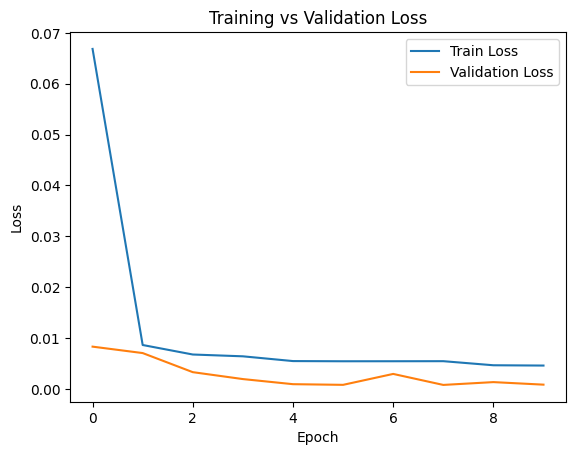

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training vs Validation Loss")
plt.show()

#GRAFIK PERBANDINGAN

In [ ]:
prediction_columns = [
    'pred_open',
    'pred_high',
    'pred_low',
    'pred_close',
    'pred_open_high',
    'pred_open_low',
    'pred_open_close',
    'pred_high_low',
    'pred_high_close',
    'pred_low_close',
    'pred_open_high_low',
    'pred_open_high_close',
    'pred_open_low_close',
    'pred_high_low_close',
    'pred_open_high_low_close'
]

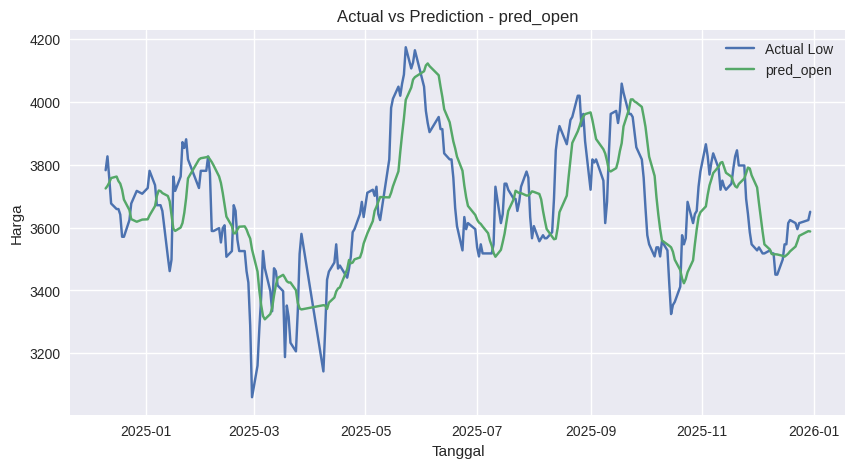

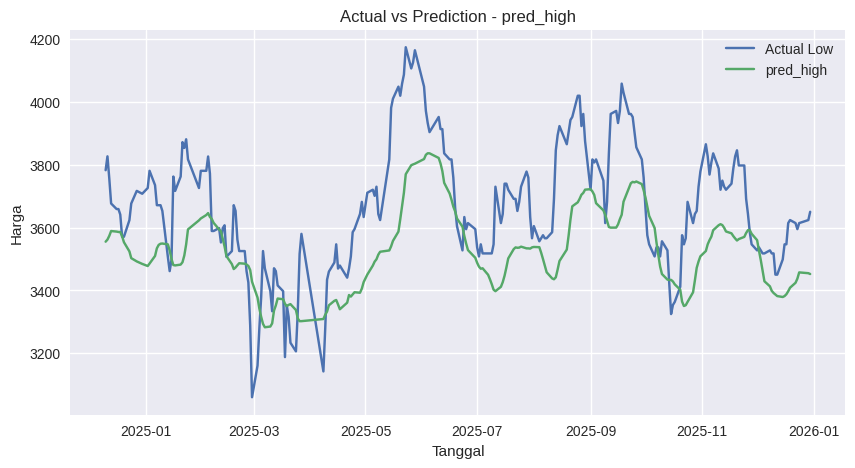

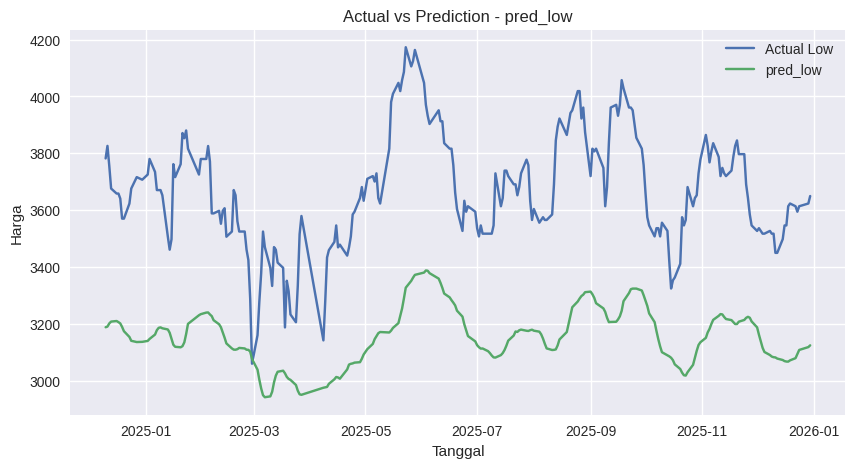

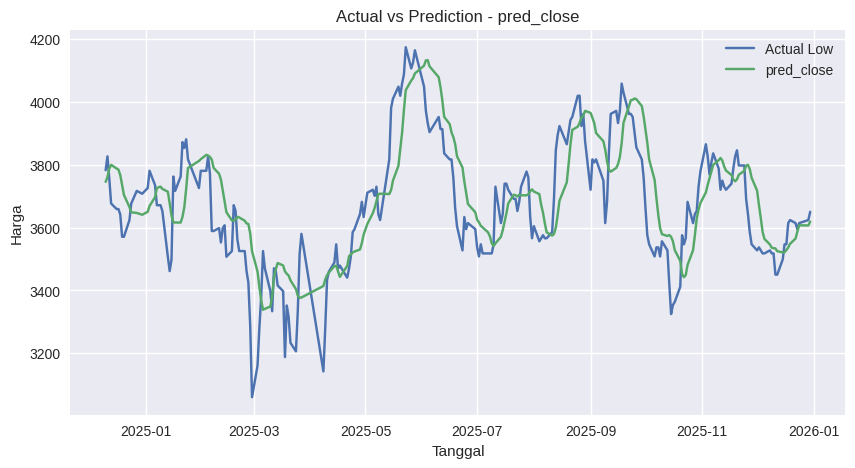

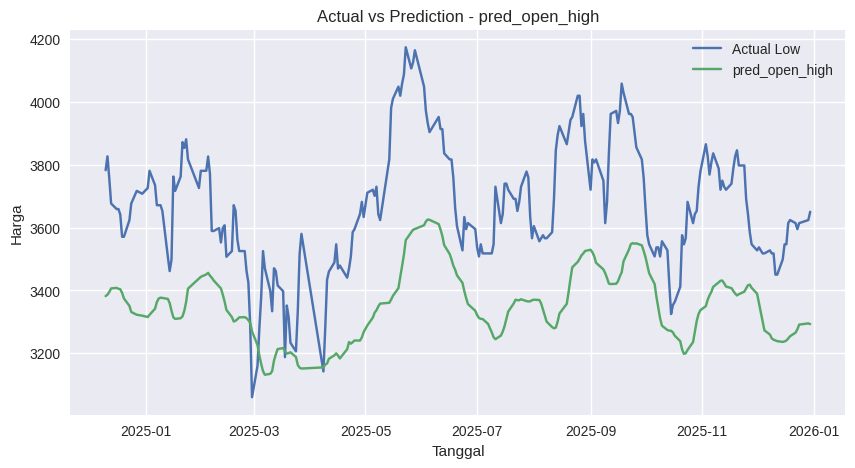

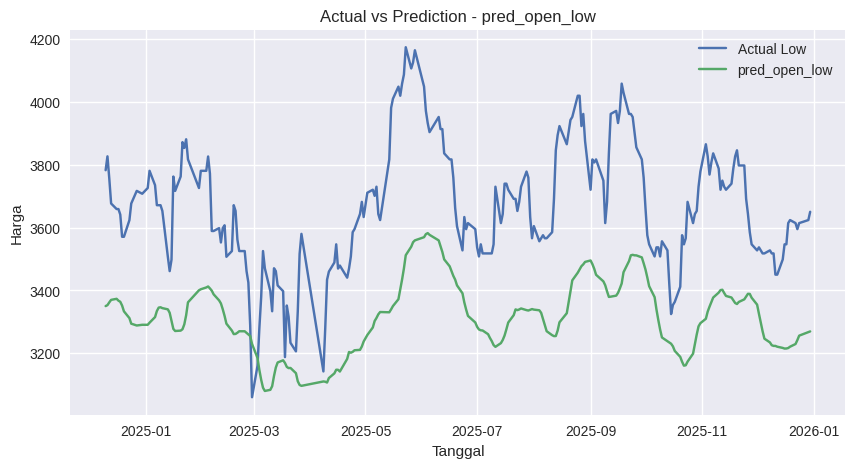

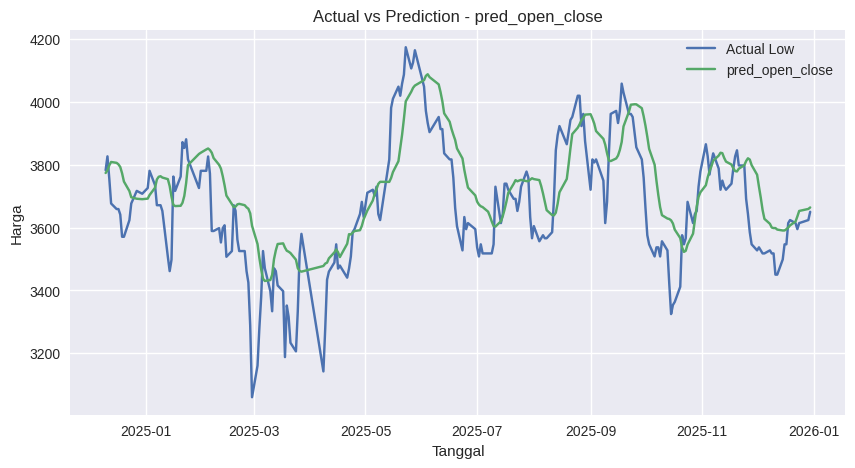

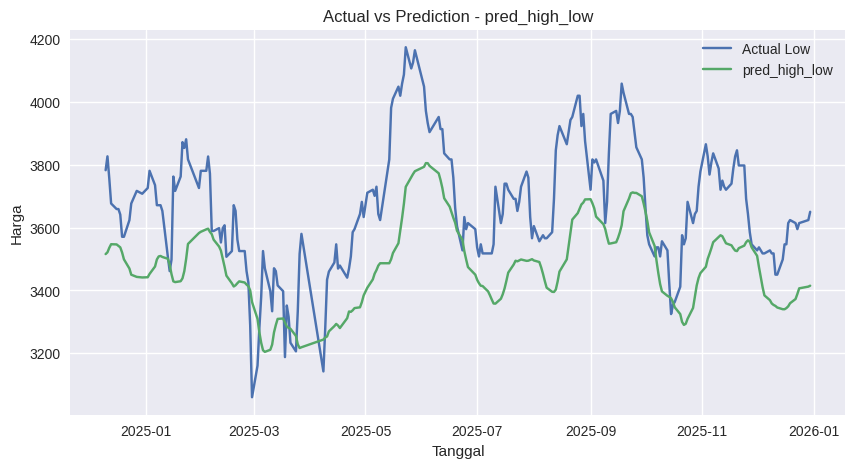

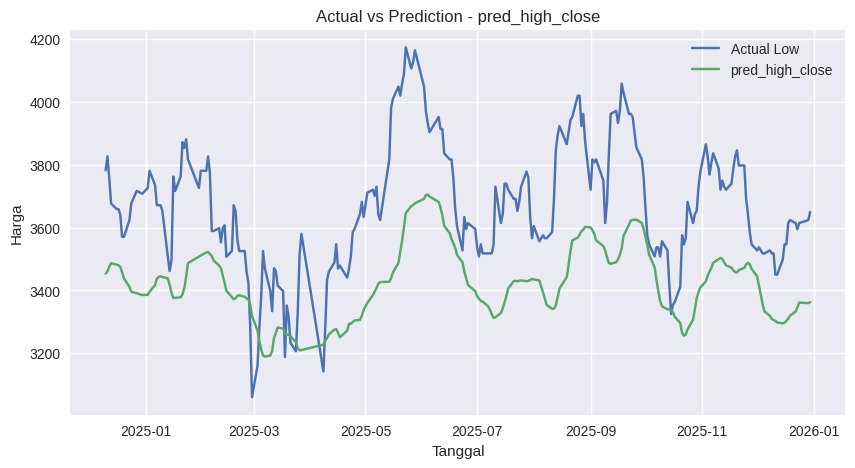

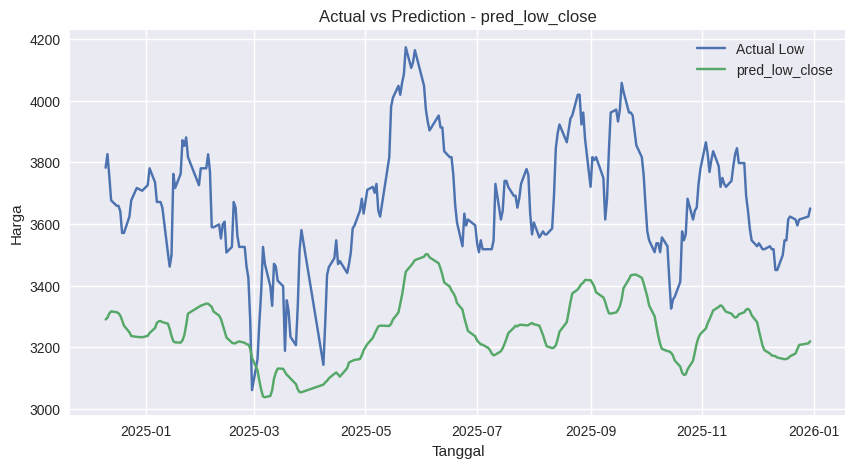

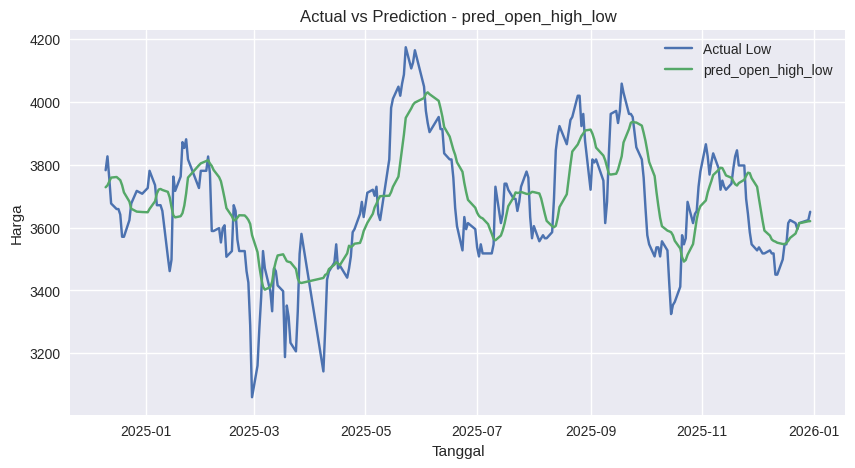

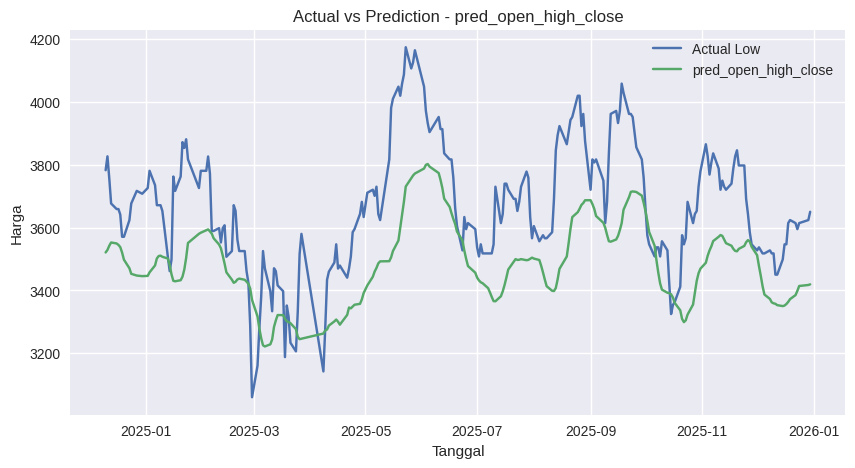

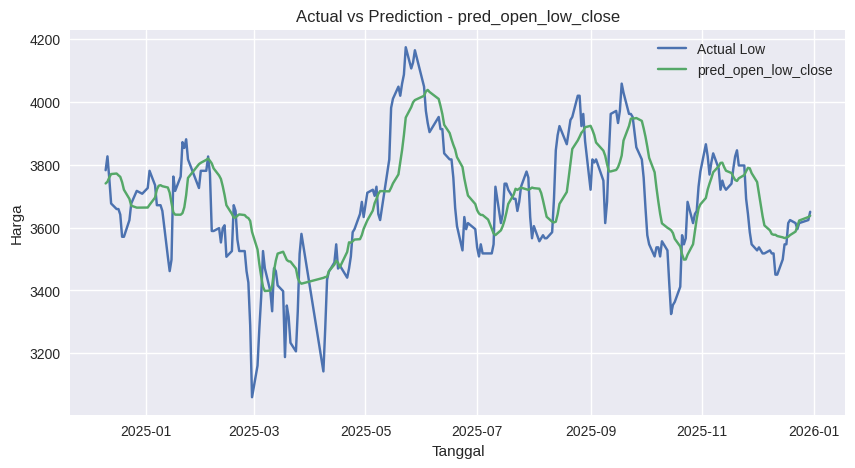

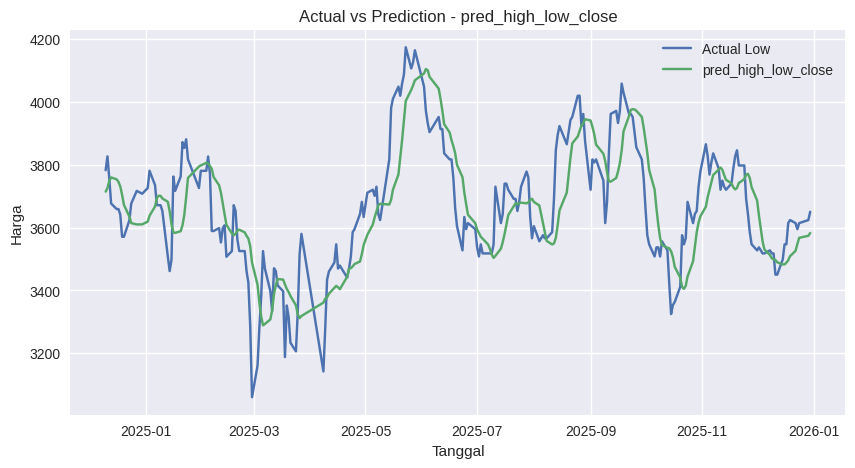

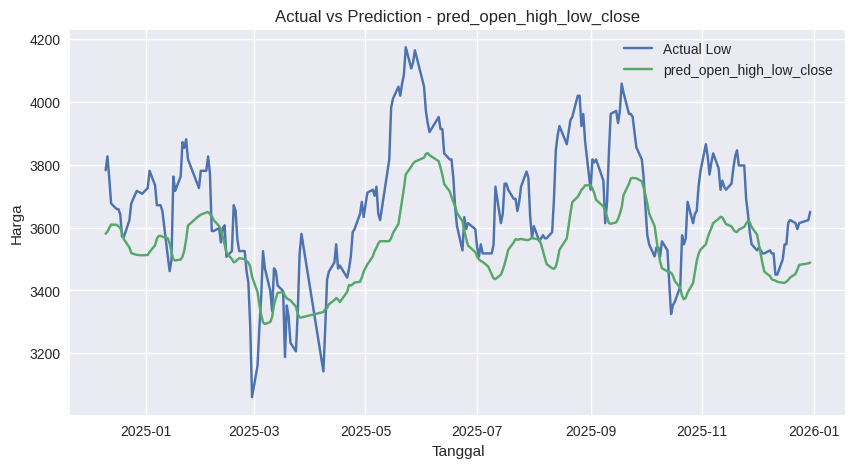

In [ ]:
#GANTI
import matplotlib.pyplot as plt

for col in prediction_columns:
    plt.style.use("seaborn-v0_8")
    plt.figure(figsize=(10,5))

    plt.plot(results_df["date"], results_df["actual_low"], label="Actual Low")
    plt.plot(results_df["date"], results_df[col], label=col)

    plt.title(f"Actual vs Prediction - {col}")
    plt.xlabel("Tanggal")
    plt.ylabel("Harga")

    plt.legend()
    plt.grid(True)

    plt.show()

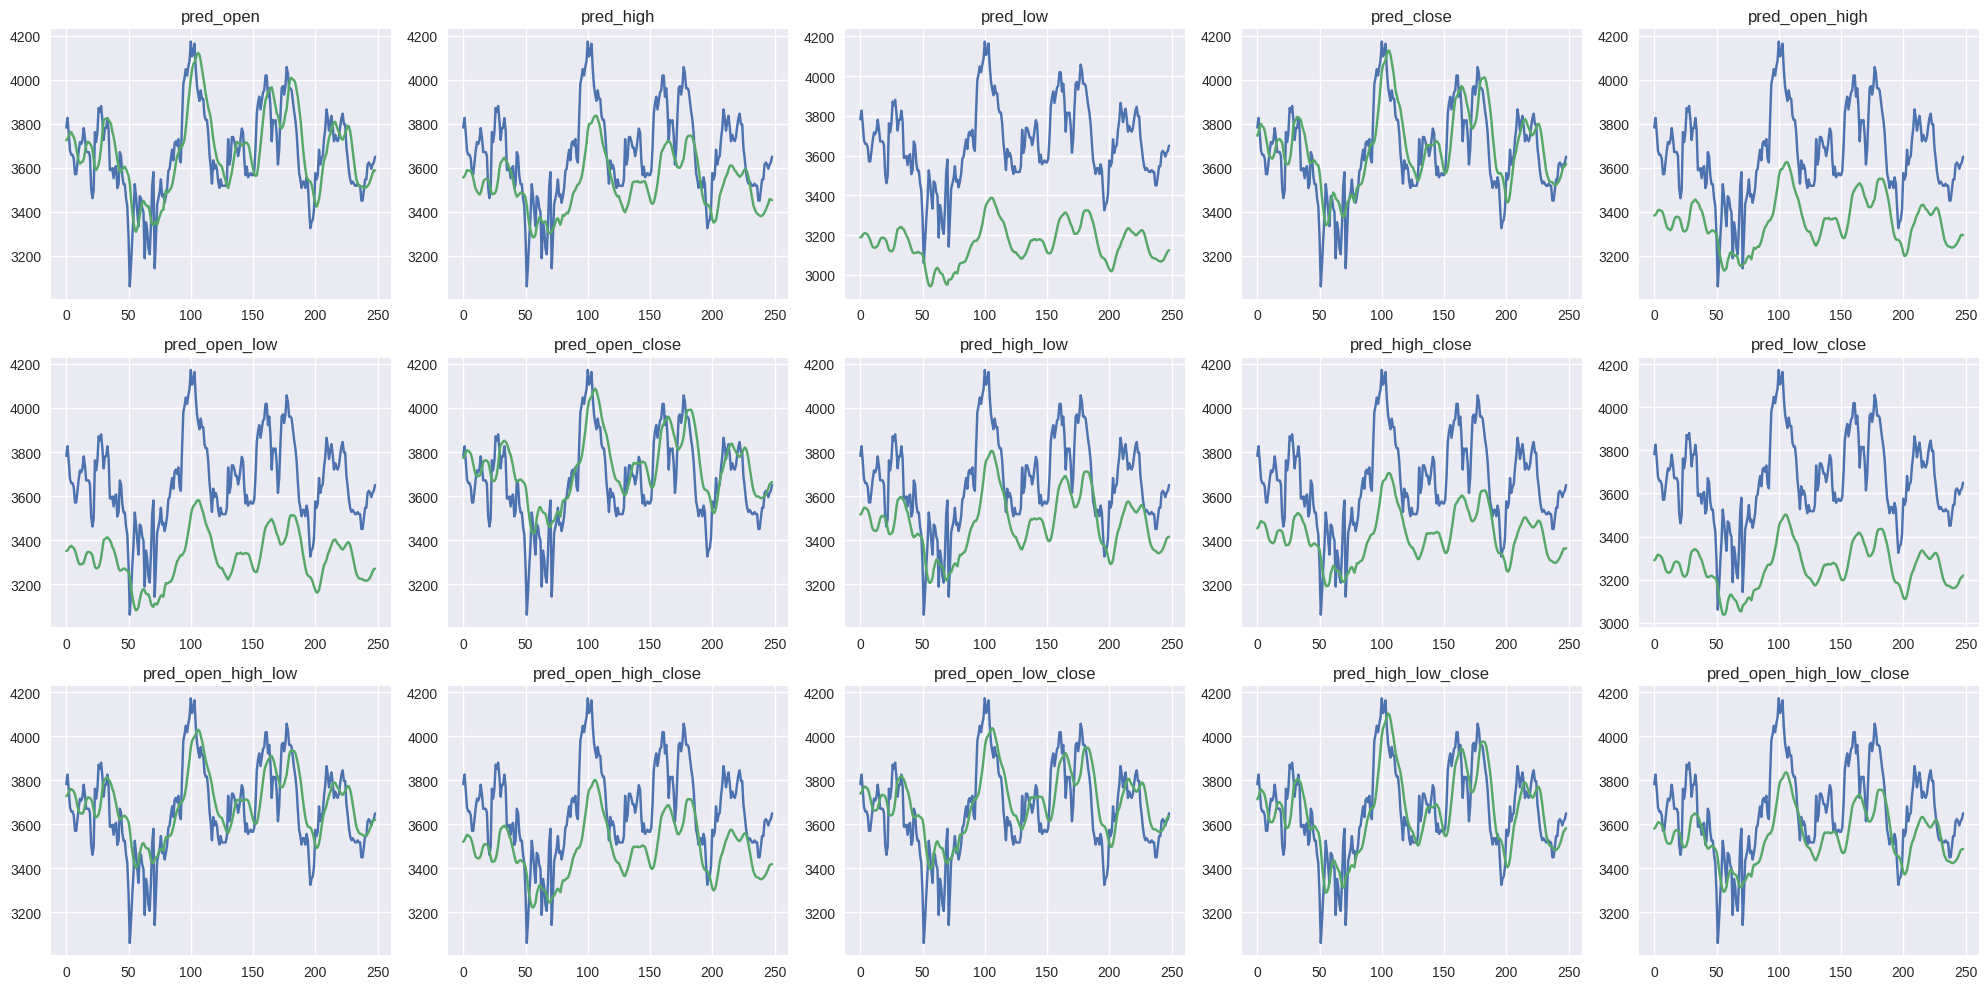

In [ ]:
#GANTI
fig, axes = plt.subplots(3,5, figsize=(20,10))
axes = axes.flatten()

for i, col in enumerate(prediction_columns):

    axes[i].plot(results_df["actual_low"], label="Actual")
    axes[i].plot(results_df[col], label="Prediksi")

    axes[i].set_title(col)
    axes[i].grid(True)

plt.style.use("seaborn-v0_8")
plt.tight_layout()
plt.show()

# MSE without DIFFERENCING

In [ ]:
prediction_columns = [
    'pred_open',
    'pred_high',
    'pred_low',
    'pred_close',
    'pred_open_high',
    'pred_open_low',
    'pred_open_close',
    'pred_high_low',
    'pred_high_close',
    'pred_low_close',
    'pred_open_high_low',
    'pred_open_high_close',
    'pred_open_low_close',
    'pred_high_low_close',
    'pred_open_high_low_close'
]

In [ ]:
#GANTI
import numpy as np
import pandas as pd

# Error setiap model
for col in prediction_columns:

    error_col = "error_" + col

    results_df[error_col] = (results_df["actual_low"] - results_df[col])**2


# MSE dan RMSE setiap model
evaluation_results = []

for col in prediction_columns:

    error_col = "error_" + col

    mse = results_df[error_col].mean()
    rmse = np.sqrt(mse)

    evaluation_results.append([col, mse, rmse])


# Membuat tabel evaluasi
tabel_evaluasi = pd.DataFrame(evaluation_results, columns=["Model", "MSE", "RMSE"])

print(tabel_evaluasi)

                       Model            MSE        RMSE
0                  pred_open   17724.010245  133.131552
1                  pred_high   37675.485306  194.101740
2                   pred_low  276859.867966  526.174750
3                 pred_close   16636.687536  128.983284
4             pred_open_high  115898.299426  340.438393
5              pred_open_low  139595.285126  373.624524
6            pred_open_close   20940.338354  144.707769
7              pred_high_low   52073.633578  228.196480
8            pred_high_close   77178.984793  277.811060
9             pred_low_close  184931.890902  430.037081
10        pred_open_high_low   17679.139936  132.962927
11      pred_open_high_close   49794.805622  223.147497
12       pred_open_low_close   18523.390840  136.100664
13       pred_high_low_close   15844.698494  125.875726
14  pred_open_high_low_close   31915.406724  178.648836


In [ ]:
# Urutan model terbaik berdasarkan MSE

tabel_evaluasi = tabel_evaluasi.sort_values(by="MSE")
print(tabel_evaluasi)

                       Model            MSE        RMSE
13       pred_high_low_close   15844.698494  125.875726
3                 pred_close   16636.687536  128.983284
10        pred_open_high_low   17679.139936  132.962927
0                  pred_open   17724.010245  133.131552
12       pred_open_low_close   18523.390840  136.100664
6            pred_open_close   20940.338354  144.707769
14  pred_open_high_low_close   31915.406724  178.648836
1                  pred_high   37675.485306  194.101740
11      pred_open_high_close   49794.805622  223.147497
7              pred_high_low   52073.633578  228.196480
8            pred_high_close   77178.984793  277.811060
4             pred_open_high  115898.299426  340.438393
5              pred_open_low  139595.285126  373.624524
9             pred_low_close  184931.890902  430.037081
2                   pred_low  276859.867966  526.174750


# PREDIKSI 7 HARI KE DEPAN

In [ ]:
#GANTI
last_sequence = X_test_high_low_close[-1]
last_sequence

array([[0.75771678, 0.75364171, 0.76579128],
       [0.76688381, 0.76954532, 0.77251768],
       [0.7646011 , 0.77179302, 0.77028152],
       [0.75771675, 0.76954531, 0.76803935],
       [0.75771678, 0.76503195, 0.77028152],
       [0.7600176 , 0.76954534, 0.77028152],
       [0.76001758, 0.771793  , 0.77251768]])

In [ ]:
#GANTI
future_predictions = []

current_sequence = last_sequence.copy()

for i in range(8):

    pred = models["low"].predict(current_sequence.reshape(1, current_sequence.shape[0], current_sequence.shape[1]))

    future_predictions.append(pred[0,0])

    # update window
    current_sequence = np.roll(current_sequence, -1, axis=0)

    # masukkan prediksi ke timestep terakhir
    current_sequence[-1, 0] = pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step

/tmp/ipykernel_1459/2876515472.py:16: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  current_sequence[-1, 0] = pred


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


In [ ]:
#GANTI
future_predictions = np.array(future_predictions).reshape(-1,1)

# inverse scaler
future_log = scaler_low.inverse_transform(future_predictions)

# inverse log
future_prices = np.exp(future_log)

future_prices = future_prices.flatten()

In [ ]:
print("Prediksi harga saham 7 hari ke depan:")

for i, price in enumerate(future_prices, start=1):
    print(f"Hari ke-{i}: {price:.2f}")

Prediksi harga saham 7 hari ke depan:
Hari ke-1: 1761.14
Hari ke-2: 1761.17
Hari ke-3: 1759.78
Hari ke-4: 1757.53
Hari ke-5: 1755.16
Hari ke-6: 1753.07
Hari ke-7: 1751.30
Hari ke-8: 1749.85
